<a href="https://colab.research.google.com/github/192565074simats-code/MLA0201/blob/main/Experiment_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TRAINING DATASET


,Sky,AirTemp,Humidity,Wind,Water,Forecast,EnjoySport
0,Sunny,Warm,Normal,Strong,Warm,Same,Yes
1,Sunny,Warm,High,Strong,Warm,Same,Yes
2,Rainy,Cold,High,Strong,Warm,Change,No
3,Sunny,Warm,High,Strong,Cool,Same,Yes
4,Sunny,Warm,Normal,Weak,Warm,Same,Yes



FINAL HYPOTHESIS
Sky: Sunny
AirTemp: Warm
Humidity: ?
Wind: ?
Water: ?
Forecast: Same

Final Hypothesis: ['Sunny', 'Warm', '?', '?', '?', 'Same']


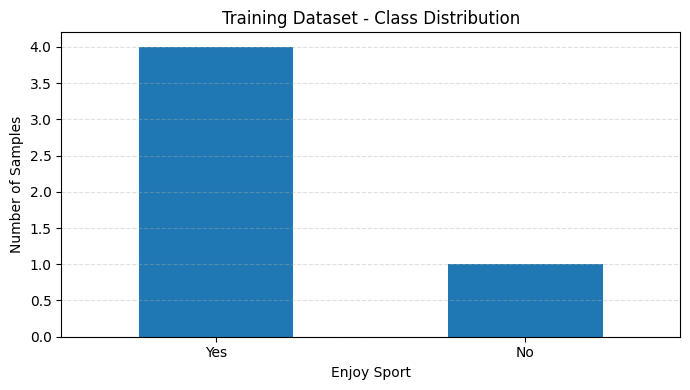

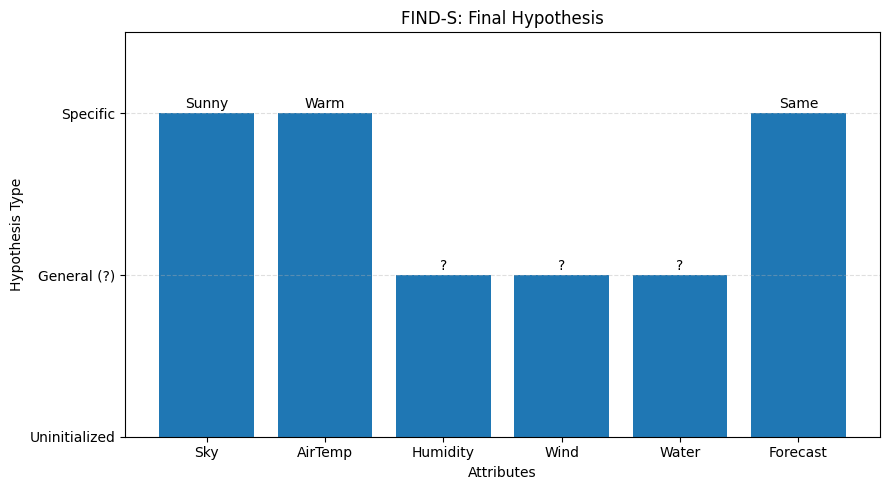

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Create the training dataset
data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High', 'Normal'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Strong', 'Weak'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool', 'Warm'],
    'Forecast': ['Same', 'Same', 'Change', 'Same', 'Same'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes', 'Yes']
}

df = pd.DataFrame(data)

print("TRAINING DATASET")
display(df)

# 2. Implement FIND-S algorithm
attributes = list(df.columns[:-1])
hypothesis = ['0'] * len(attributes)
steps = []

for index, row in df.iterrows():
    if row['EnjoySport'] == 'Yes':
        for i, attribute in enumerate(attributes):
            if hypothesis[i] == '0':
                hypothesis[i] = row[attribute]
            elif hypothesis[i] != row[attribute]:
                hypothesis[i] = '?'

        steps.append(hypothesis.copy())

# 3. Display final hypothesis
print("\nFINAL HYPOTHESIS")
for attribute, value in zip(attributes, hypothesis):
    print(f"{attribute}: {value}")

print("\nFinal Hypothesis:", hypothesis)

# 4. Plot training data labels
plt.figure(figsize=(7, 4))
df['EnjoySport'].value_counts().reindex(
    ['Yes', 'No'], fill_value=0
).plot(kind='bar')

plt.title("Training Dataset - Class Distribution")
plt.xlabel("Enjoy Sport")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# 5. Plot final hypothesis
specificity = [0 if x == '0' else 1 if x == '?' else 2
               for x in hypothesis]

plt.figure(figsize=(9, 5))
bars = plt.bar(attributes, specificity)

labels = {
    0: "Uninitialized",
    1: "General (?)",
    2: "Specific value"
}

for bar, value in zip(bars, hypothesis):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.03,
        str(value),
        ha='center',
        fontsize=10
    )

plt.title("FIND-S: Final Hypothesis")
plt.xlabel("Attributes")
plt.ylabel("Hypothesis Type")
plt.yticks([0, 1, 2], ["Uninitialized", "General (?)", "Specific"])
plt.ylim(0, 2.5)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()